In [1]:
import sys
sys.path.append('../')
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
from hypgs.models.hsn_pyg import HyperScatteringModule
from hypgs.utils.data import get_hyperedge_index
import scanpy as sc
import numpy as np
import pandas as pd
import torch
from torch_geometric.utils.convert import from_networkx
from hypgs.utils.data import HGDataset
from dhg import Hypergraph
import scprep
import matplotlib.pyplot as plt
import re
import phate
from phate.cluster import kmeans

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:47: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/libpyg.so: undefined symbol: _ZN2at4_ops12split_Tensor4callERKNS_6TensorEN3c106SymIntEl
  warnings.warn(f"An issue occurred while importing 'pyg-lib'. "
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:90: UserWarning: An issue occurred while importing 'torch-spline-conv'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.con

In [2]:
import sys
sys.path.append('../')
import scanpy as sc
import numpy as np
import torch
import scprep
import matplotlib.pyplot as plt
import re
import phate
from phate.cluster import kmeans

In [3]:
adata = sc.read_h5ad("../data/A23-290-CP_preprocessed_new.h5ad")

In [4]:
adata_subset = adata

In [5]:
matches = [bool(re.search('myl|myh|cald|mgp', name.lower())) for name in adata_subset.var.index]
# matches = matches & adata_subset.var['highly_variable']
markers = adata_subset.var[matches].index.tolist()
# markers = [m for m in markers if m not in ['MYH10', 'MYLK']]

In [6]:
markers

['MYLK-AS1',
 'MYLK4',
 'MYL6P1',
 'MYL9',
 'MYL12B',
 'MYH9',
 'CALD1',
 'MYL6',
 'MYH10',
 'MYH11',
 'MGP',
 'MYL6B',
 'MYHAS',
 'ATP5MGP6',
 'MYL6P2',
 'MYLK3',
 'MYL12A',
 'MYL6P3',
 'MYLPF',
 'MYH3',
 'MYLK',
 'NCALD',
 'MYLIP',
 'MYH7',
 'MYL6P5',
 'MYH7B',
 'MYH6',
 'MYL10']

In [7]:
len(markers)

28

In [1]:
import magic
magic_op = magic.MAGIC()
adata_magic = magic_op.fit_transform(adata, genes=markers)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'adata' is not defined

In [11]:
adata_magic

AnnData object with n_obs × n_vars = 21331 × 28
    obs: 'n_counts_all'
    var: 'n_counts'

In [21]:
adata_magic.write_h5ad("../data/A23-290-CP_preprocessed_new_magic.h5ad")

In [8]:
# adata_magic = sc.read_h5ad("../data/A23-290-CP_preprocessed_new_magic.h5ad")

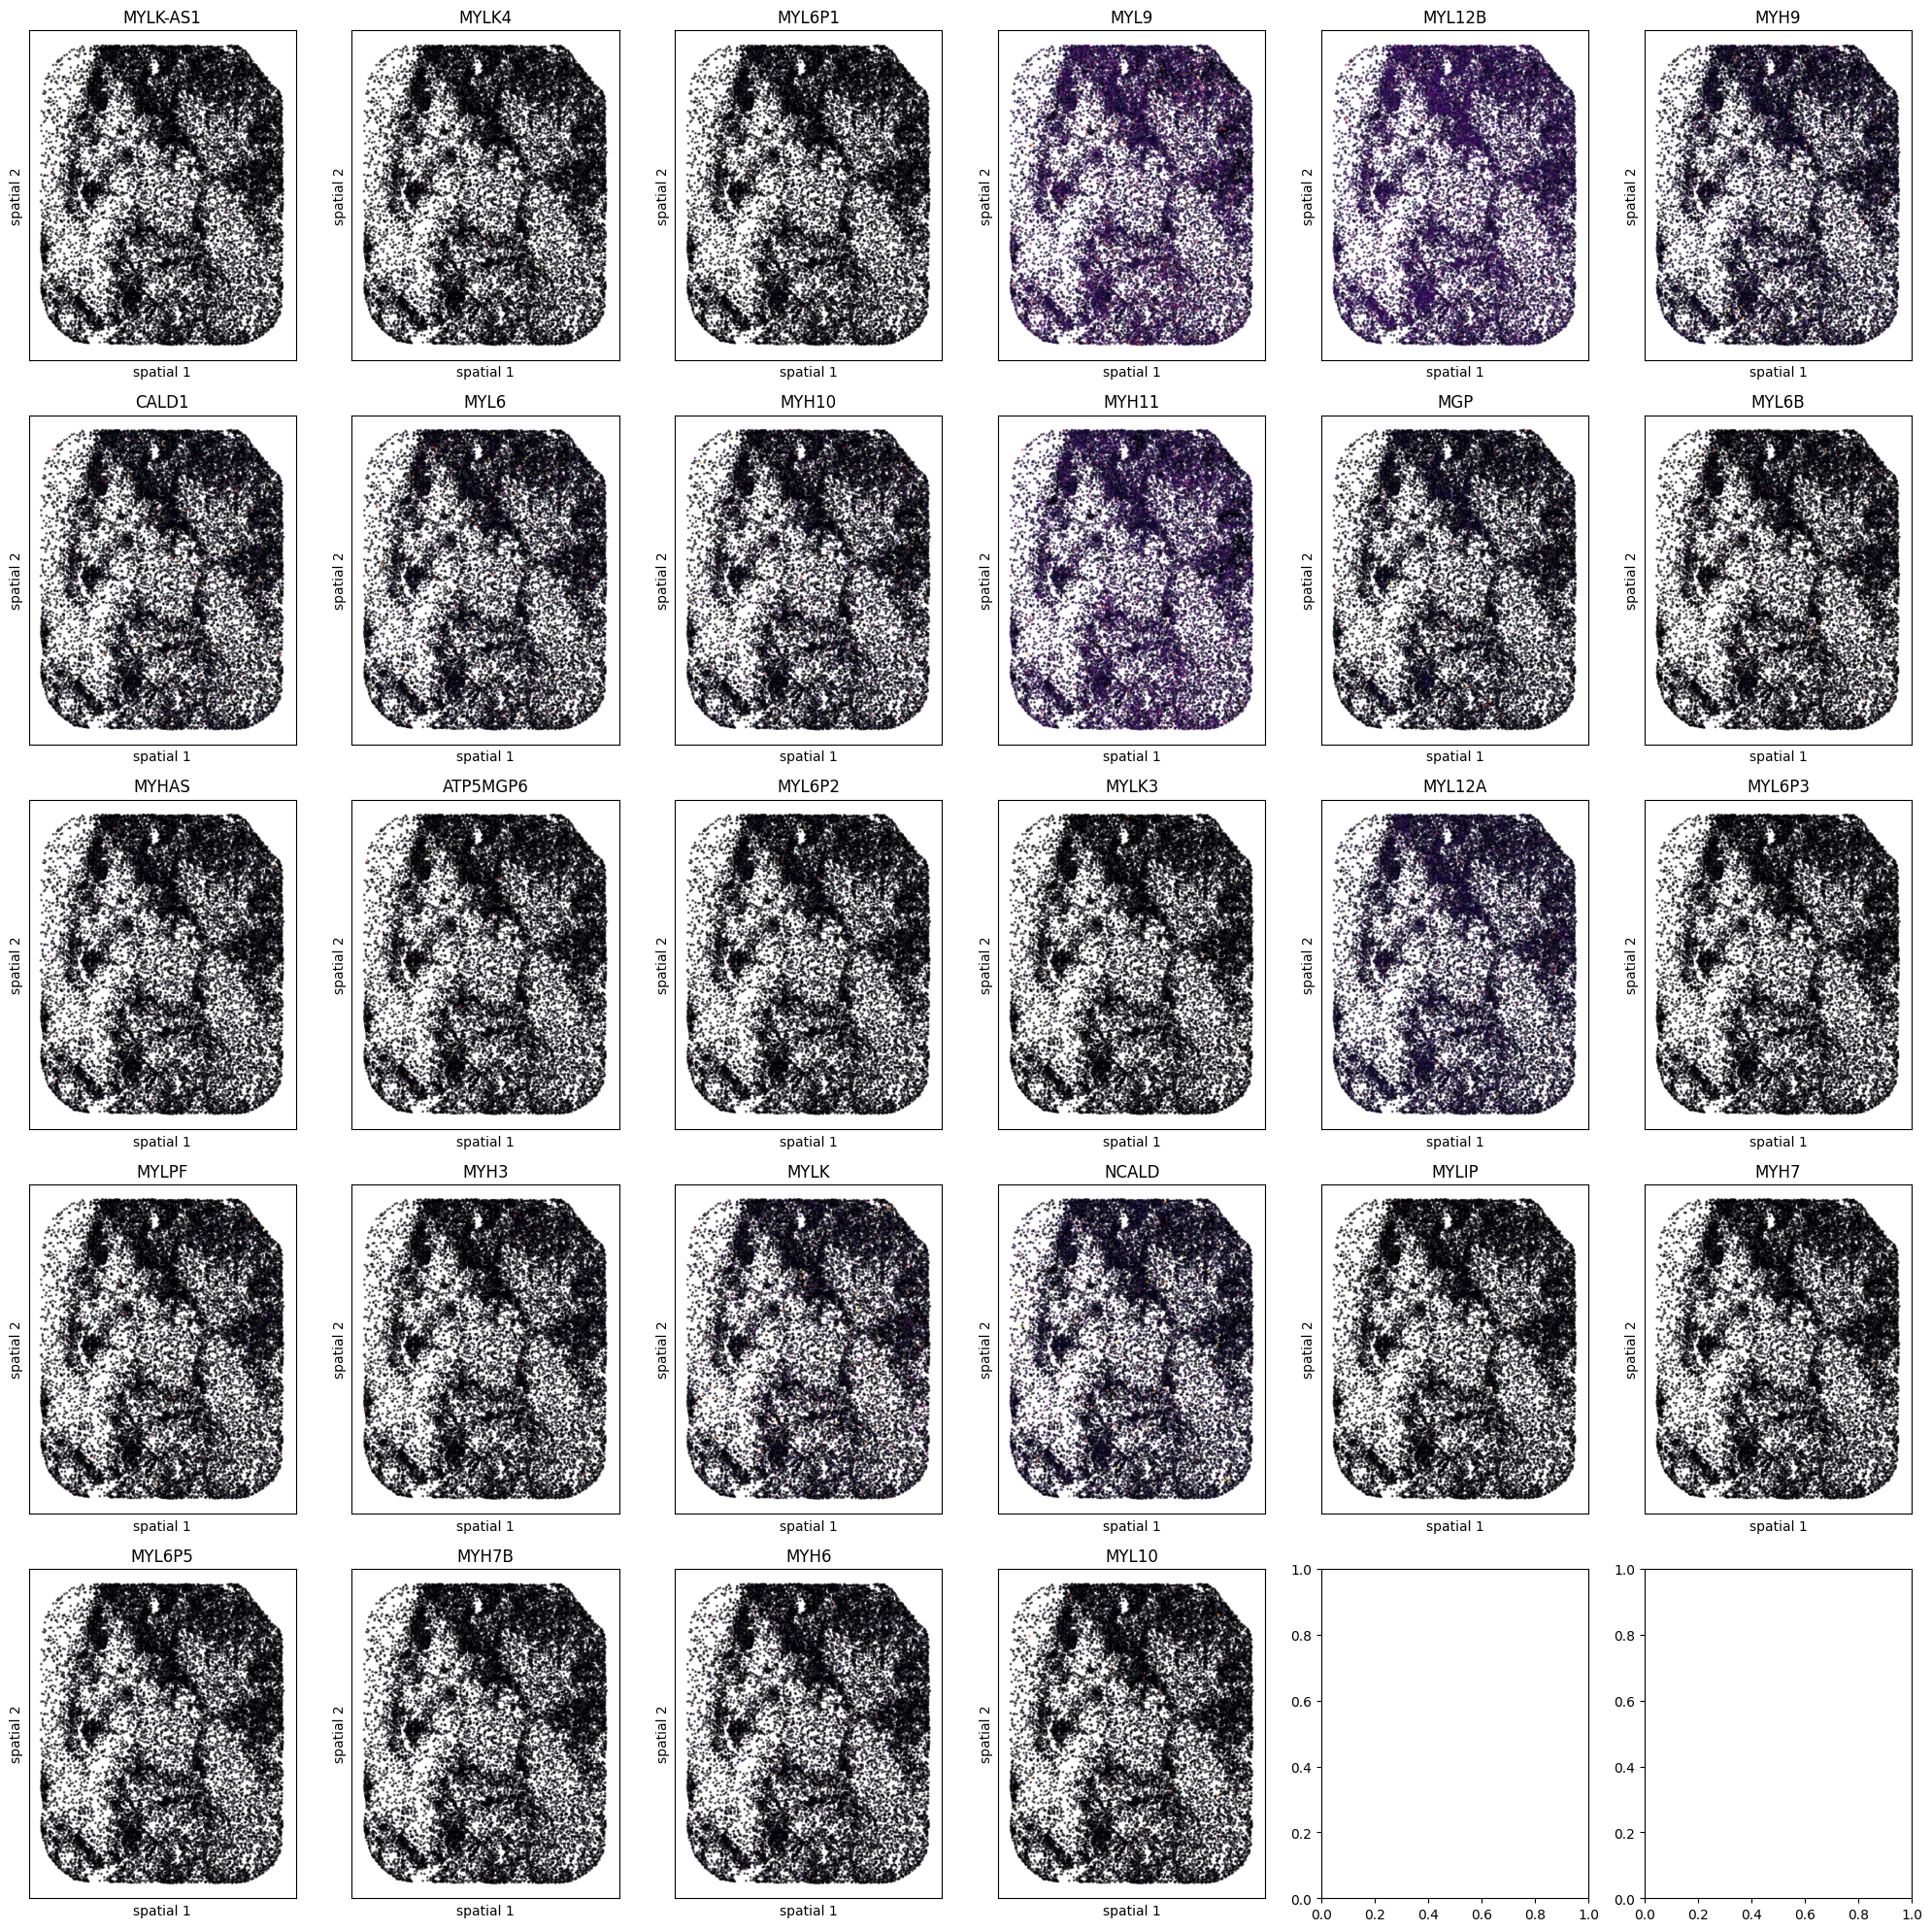

In [9]:
fig, axes = plt.subplots(5, 6, figsize=(20, 20))

for i, marker in enumerate(markers):
    node_feat = adata_magic[:, marker].X.toarray()
    ax = axes[i // 6, i % 6]
    scprep.plot.scatter2d(adata.obsm['X_spatial'], c=node_feat, s=1, alpha=.5, ax=ax, colorbar=False)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


In [ ]:
coordinates = adata_subset.obsm['X_spatial']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])
cell_data = pd.DataFrame(np.c_[adata_subset.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

In [ ]:
X_cmbn = adata_subset.X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X_cmbn)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 1)
dataset = HGDataset(original_dataset, to_hg_func)

In [ ]:
len(markers)